Importing the necessary libraries.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import plotly.express as px

In [2]:
pd.set_option("display.max_columns", None)

df = pd.read_csv('world-data-2023.csv')
df

,Country,Density\n(P/Km2),Abbreviation,Agricultural Land( %),Land Area(Km2),Armed Forces size,Birth Rate,Calling Code,Capital/Major City,Co2-Emissions,CPI,CPI Change (%),Currency-Code,Fertility Rate,Forested Area (%),Gasoline Price,GDP,Gross primary education enrollment (%),Gross tertiary education enrollment (%),Infant mortality,Largest city,Life expectancy,Maternal mortality ratio,Minimum wage,Official language,Out of pocket health expenditure,Physicians per thousand,Population,Population: Labor force participation (%),Tax revenue (%),Total tax rate,Unemployment rate,Urban_population,Latitude,Longitude
0,Afghanistan,60,AF,58.10%,"652,230","323,000",32.49,93.0,Kabul,"8,672",149.9,2.30%,AFN,4.47,2.10%,$0.70,"$19,101,353,833",104.00%,9.70%,47.9,Kabul,64.5,638.0,$0.43,Pashto,78.40%,0.28,"38,041,754",48.90%,9.30%,71.40%,11.12%,"9,797,273",33.939110,67.709953
1,Albania,105,AL,43.10%,"28,748","9,000",11.78,355.0,Tirana,"4,536",119.05,1.40%,ALL,1.62,28.10%,$1.36,"$15,278,077,447",107.00%,55.00%,7.8,Tirana,78.5,15.0,$1.12,Albanian,56.90%,1.20,"2,854,191",55.70%,18.60%,36.60%,12.33%,"1,747,593",41.153332,20.168331
2,Algeria,18,DZ,17.40%,"2,381,741","317,000",24.28,213.0,Algiers,"150,006",151.36,2.00%,DZD,3.02,0.80%,$0.28,"$169,988,236,398",109.90%,51.40%,20.1,Algiers,76.7,112.0,$0.95,Arabic,28.10%,1.72,"43,053,054",41.20%,37.20%,66.10%,11.70%,"31,510,100",28.033886,1.659626
3,Andorra,164,AD,40.00%,468,NaN,7.20,376.0,Andorra la Vella,469,NaN,NaN,EUR,1.27,34.00%,$1.51,"$3,154,057,987",106.40%,NaN,2.7,Andorra la Vella,NaN,NaN,$6.63,Catalan,36.40%,3.33,"77,142",NaN,NaN,NaN,NaN,"67,873",42.506285,1.521801
4,Angola,26,AO,47.50%,"1,246,700","117,000",40.73,244.0,Luanda,"34,693",261.73,17.10%,AOA,5.52,46.30%,$0.97,"$94,635,415,870",113.50%,9.30%,51.6,Luanda,60.8,241.0,$0.71,Portuguese,33.40%,0.21,"31,825,295",77.50%,9.20%,49.10%,6.89%,"21,061,025",-11.202692,17.873887
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,Venezuela,32,VE,24.50%,"912,050","343,000",17.88,58.0,Caracas,"164,175","2,740.27",254.90%,VED,2.27,52.70%,$0.00,"$482,359,318,768",97.20%,79.30%,21.4,Caracas,72.1,125.0,$0.01,Spanish,45.80%,1.92,"28,515,829",59.70%,NaN,73.30%,8.80%,"25,162,368",6.423750,-66.589730
191,Vietnam,314,VN,39.30%,"331,210","522,000",16.75,84.0,Hanoi,"192,668",163.52,2.80%,VND,2.05,48.10%,$0.80,"$261,921,244,843",110.60%,28.50%,16.5,Ho Chi Minh City,75.3,43.0,$0.73,Vietnamese,43.50%,0.82,"96,462,106",77.40%,19.10%,37.60%,2.01%,"35,332,140",14.058324,108.277199
192,Yemen,56,YE,44.60%,"527,968","40,000",30.45,967.0,Sanaa,"10,609",157.58,8.10%,YER,3.79,1.00%,$0.92,"$26,914,402,224",93.60%,10.20%,42.9,Sanaa,66.1,164.0,NaN,Arabic,81.00%,0.31,"29,161,922",38.00%,NaN,26.60%,12.91%,"10,869,523",15.552727,48.516388
193,Zambia,25,ZM,32.10%,"752,618","16,000",36.19,260.0,Lusaka,"5,141",212.31,9.20%,ZMW,4.63,65.20%,$1.40,"$23,064,722,446",98.70%,4.10%,40.4,Lusaka,63.5,213.0,$0.24,English,27.50%,1.19,"17,861,030",74.60%,16.20%,15.60%,11.43%,"7,871,713",-13.133897,27.849332


Here are the almost all necessary information about our dataset. As we can see our dataset includes 35 columns and 195 rows.
Dataset has null values in various features, but not that much considering its size. 
Dataset has no duplicate values which is fine.
And i listed the countries that have lots of null values. We had to remove them from our dataset for the obvious reasons. It would not be healthy to
manually fill that much null value in a one country. Problem with the countries with lots of null values could be related to political reasons or data entry problems. 

In [3]:
print("--- Data Info ---")
df.info()

print(f"\n--- Null Values ---\n{df.isnull().sum()}")

print(f"\n--- Duplicate Values ---\n{df.duplicated().sum()}")

print("--- Stats of Data ---")
print(df.describe())

missing_per_row = df.isna().sum(axis=1)
missing_summary = pd.DataFrame({'Country': df['Country'], 'Missing_Count': missing_per_row}).sort_values('Missing_Count', ascending=False)
print("\n--- Countries With Lots of Null Values ---")
print(missing_summary.head(20))


--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 35 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Country                                    195 non-null    str    
 1   Density
(P/Km2)                            195 non-null    str    
 2   Abbreviation                               188 non-null    str    
 3   Agricultural Land( %)                      188 non-null    str    
 4   Land Area(Km2)                             194 non-null    str    
 5   Armed Forces size                          171 non-null    str    
 6   Birth Rate                                 189 non-null    float64
 7   Calling Code                               194 non-null    float64
 8   Capital/Major City                         192 non-null    str    
 9   Co2-Emissions                              188 non-null    str    
 10  CPI                

Now, in order to take advantage of numerical values, we have to remove their symbols such as '%' or '$'. Otherwise Python will mark this values as 
string values. Also we have to fix the datatypes, since there are numerical values that assigned to string type, or float values assigned to integer type. In this process, the countries with null values more than 10 also removed. 

I grouped the columns that includes null values. The important columns are the ones that impossible to impute with median, mean or anything like that.
Median columns are the columns that null values will be imputed with the 'median' value of that column. I choose the median, not the mean, because of 
the potantiel outliers. And i also removed the 'minimum wage' column, becuase it is a complicated metric. Some countries have, some countries don't etc..

In [4]:
#Removing the percentage symbol for changing these numerical values into data type float.
percentage_values = ['Agricultural Land( %)', 'CPI Change (%)', 'Forested Area (%)', 'Gross primary education enrollment (%)',
                    'Gross tertiary education enrollment (%)', 'Out of pocket health expenditure', 'Population: Labor force participation (%)',
                    'Tax revenue (%)']

for col in percentage_values:
    df[col] = df[col].astype(str).str.strip().str.replace('%', '').astype(float) / 100



#Removing the dollar symbol for changing these numerical values into data type float, just like i did just before with the percentage symbol.
dollar_values = ['Gasoline Price', 'GDP', 'Minimum wage']

for col in dollar_values:
    df[col] = df[col].astype(str).str.strip().str.replace(',', '', regex=False).str.replace('$', '', regex=False).astype(float)



#Correcting the other datatypes. (There are few %'s that i didn't see, so i still had to remove %'s from them :) Looks weird but sorry. It is what it is.)
to_int = ['Density\n(P/Km2)', 'Land Area(Km2)', 'Armed Forces size']
to_float = ['Co2-Emissions','CPI','Population','Total tax rate','Unemployment rate','Urban_population']

for col in to_int:
    df[col] = df[col].astype(str).str.replace(',', '', regex=False).str.strip().astype("Int64")

for col in to_float:
     df[col] = df[col].astype(str).str.replace(',', '', regex=False).str.replace('%', '').str.strip().astype(float)



#Handling the null values.

#Removing countries with null values more than 10, because of possible problems in clustering. (Also, sadly, Palestine too. Free Palestine.)
countries_to_drop = missing_summary[missing_summary['Missing_Count'] >= 10]['Country']
df = df[~df['Country'].isin(countries_to_drop)]

#--These are the ones that i can't impute for obvious reasons. 
important_cols = ['Land Area(Km2)', 'Calling Code', 'GDP', 'Population', 'Latitude', 'Longitude']
df = df.dropna(subset=important_cols)

#--These are the ones that i filled with median values, because of the potential outliers.
median_fill = ['Agricultural Land( %)', 'Birth Rate', 'Co2-Emissions', 'CPI', 'CPI Change (%)', 'Fertility Rate', 'Forested Area (%)', 
               'Gross primary education enrollment (%)', 'Gross tertiary education enrollment (%)', 'Infant mortality', 'Life expectancy',
               'Maternal mortality ratio', 'Out of pocket health expenditure', 'Physicians per thousand', 'Total tax rate', 'Armed Forces size', 
               'Gasoline Price', 'Population: Labor force participation (%)', 'Tax revenue (%)', 'Unemployment rate']
for col in median_fill:
    df[col] = df[col].fillna(df[col].median())

#--I decided to remove minimum wage entirely becuase some countries have, some doesn't, hard to impute and compare etc...
df = df.drop(columns=['Minimum wage'])

df = df.reset_index(drop=True)

Now, in order to see the distribution of our numerical columns and detect the potential outliers and skewness, i compare the both
histogram and box plot. In our dataset, we have countries like 'USA', 'China', 'India' etc... that causes massive outliers, thus 
causes skewness on the graphs. 

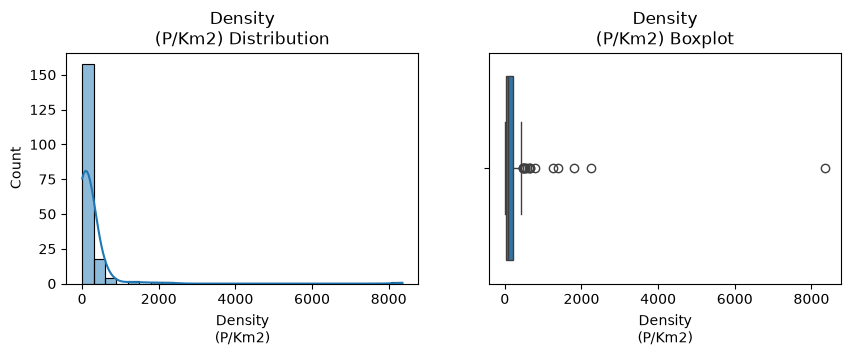

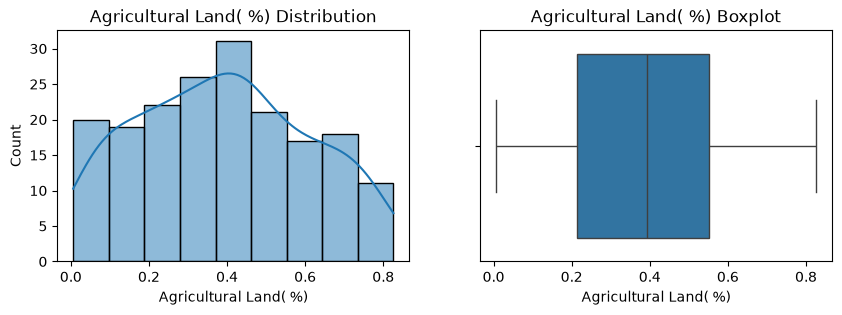

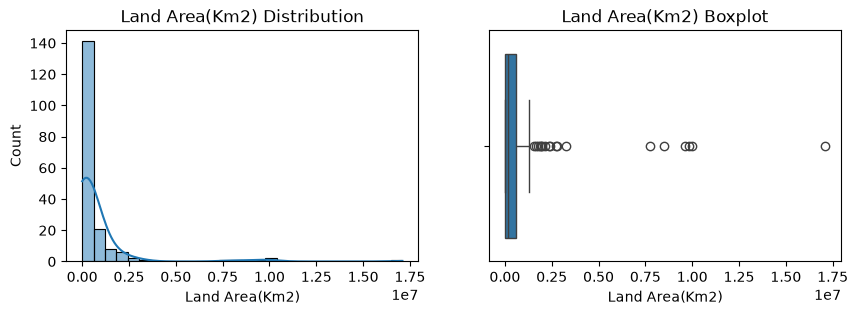

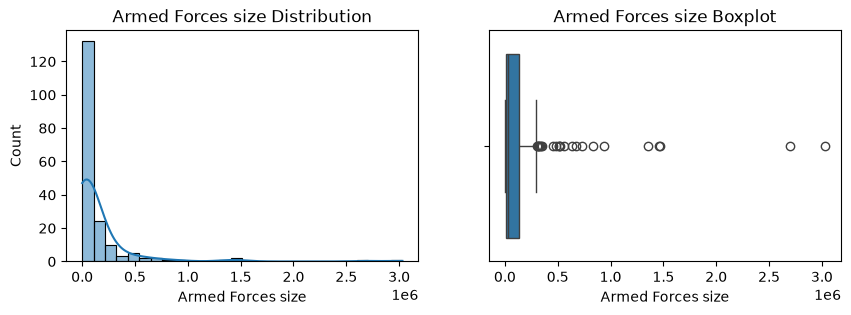

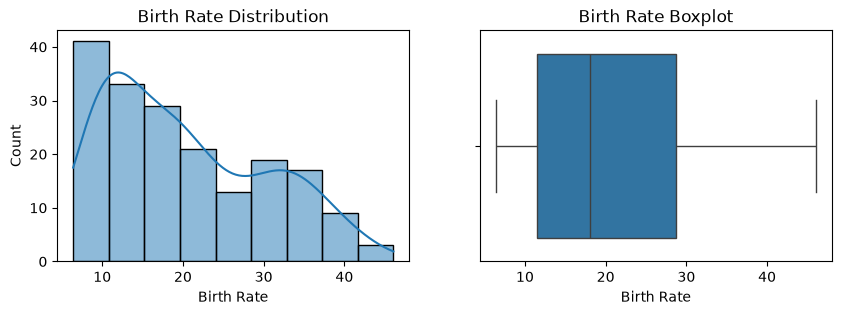

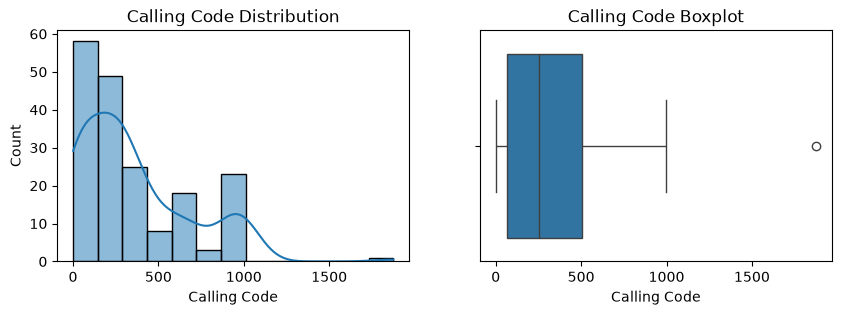

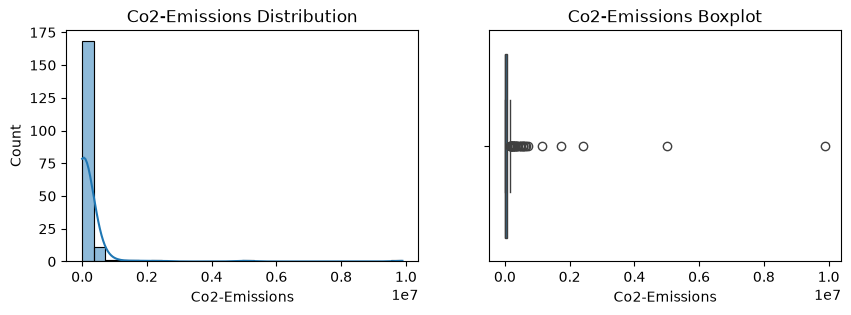

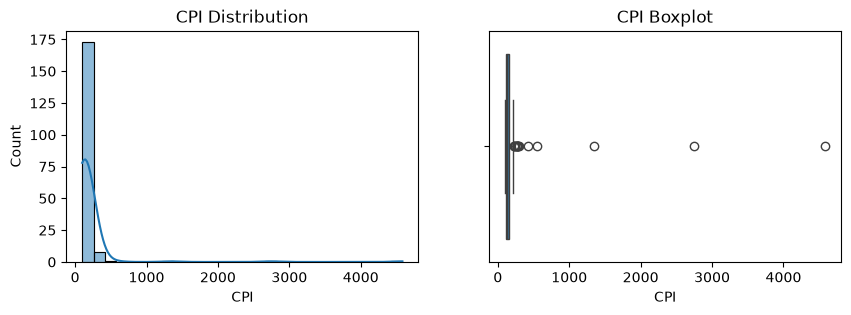

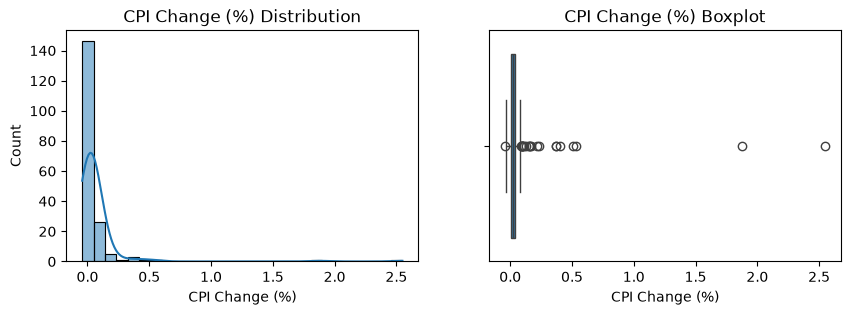

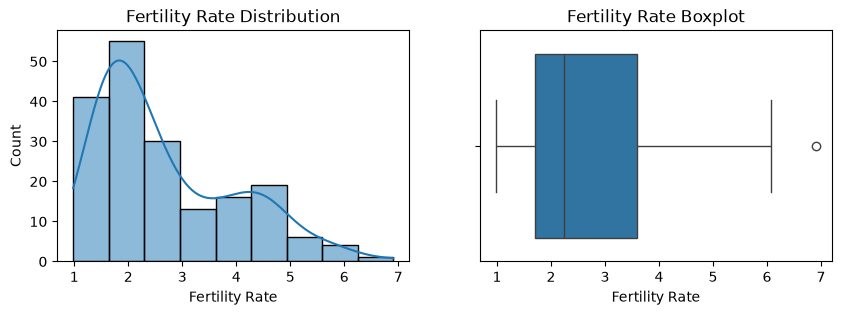

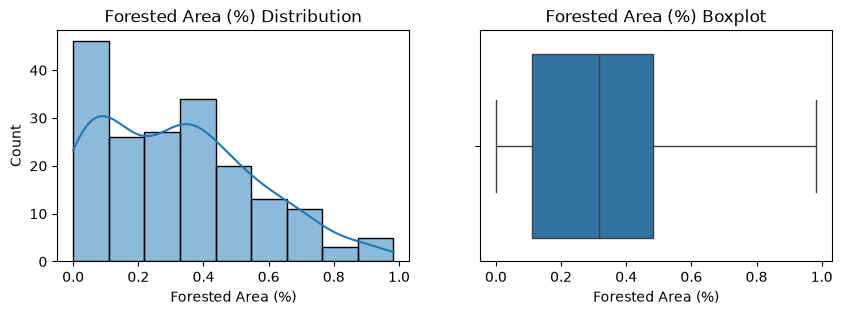

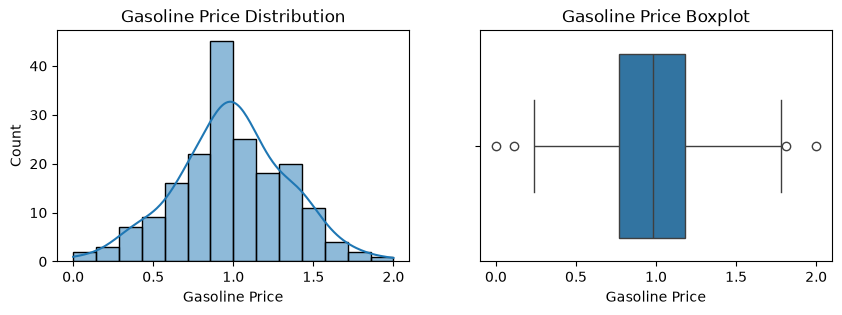

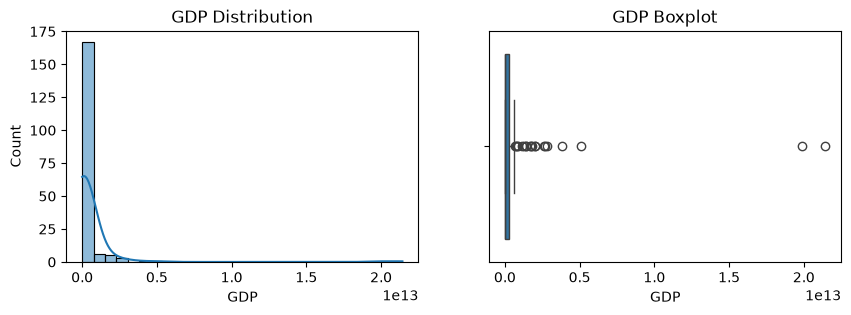

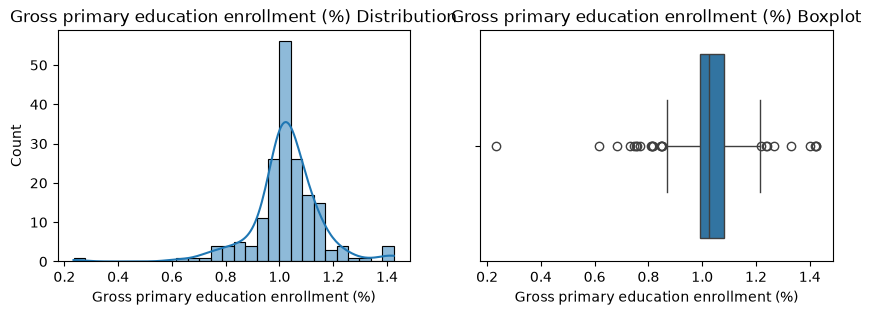

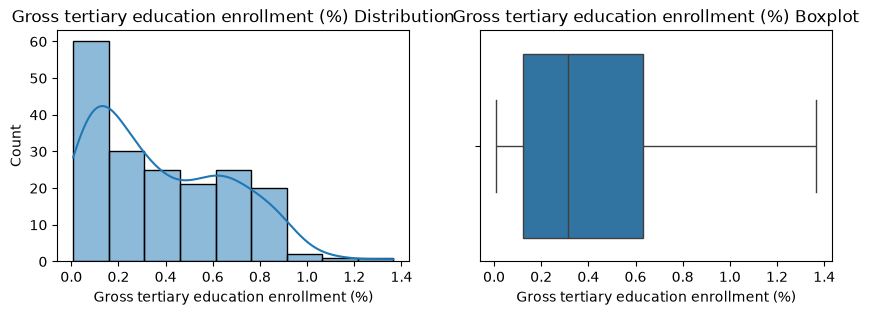

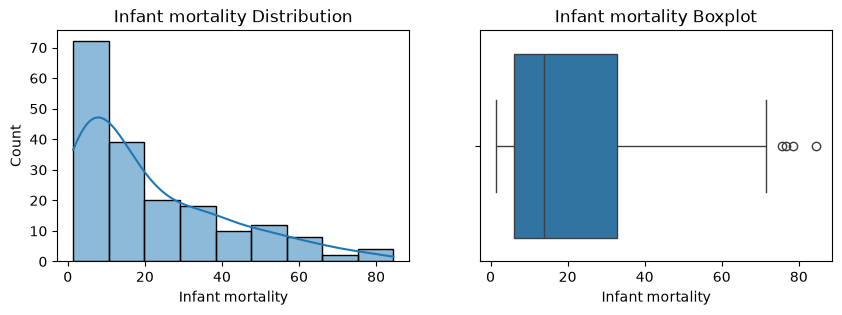

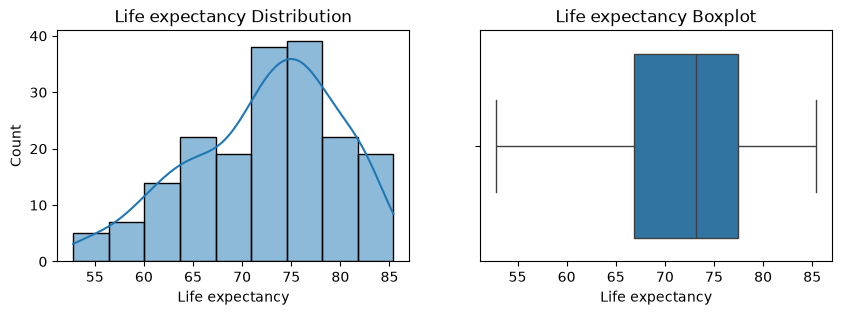

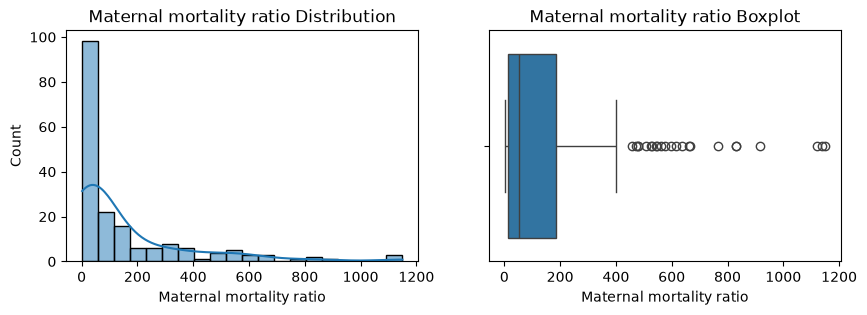

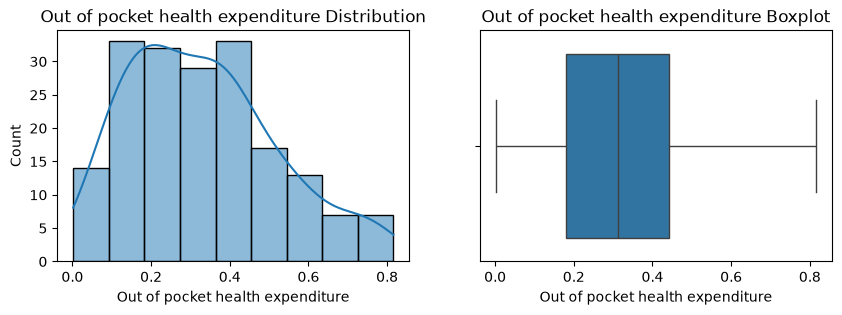

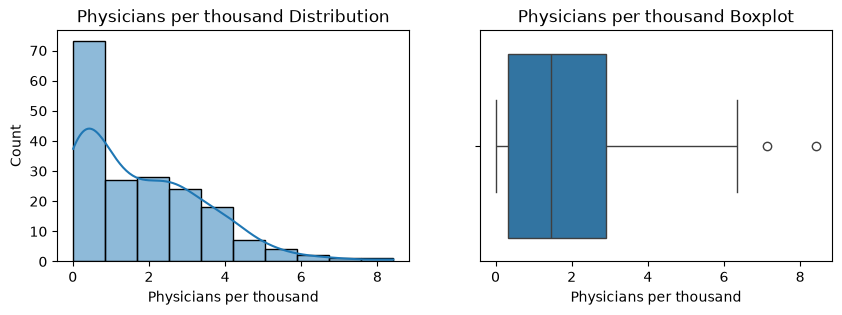

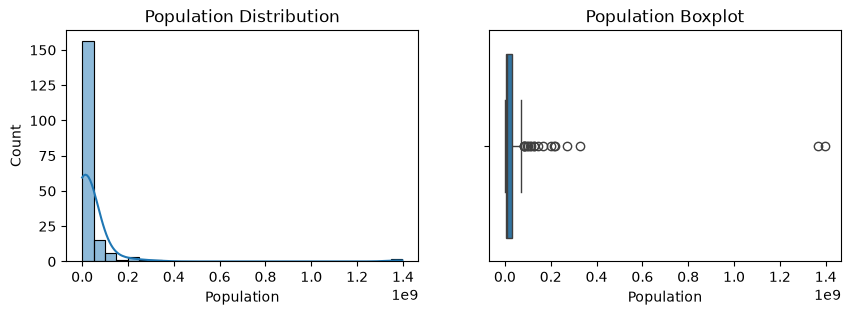

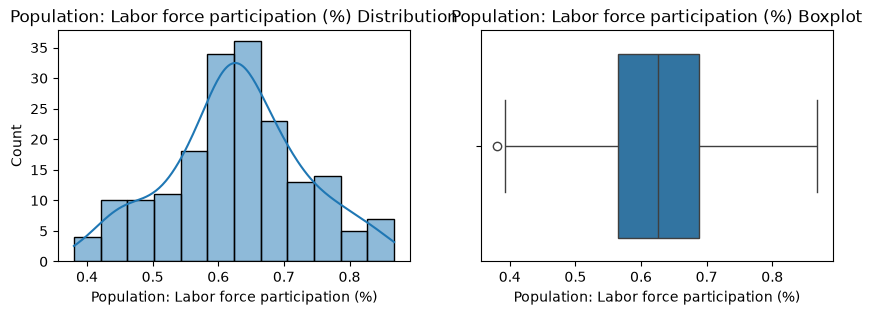

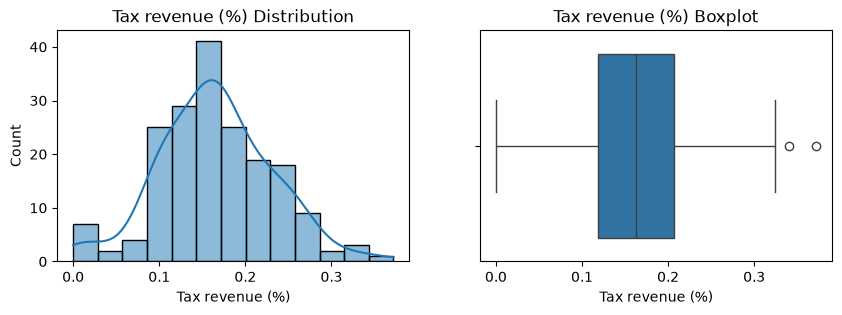

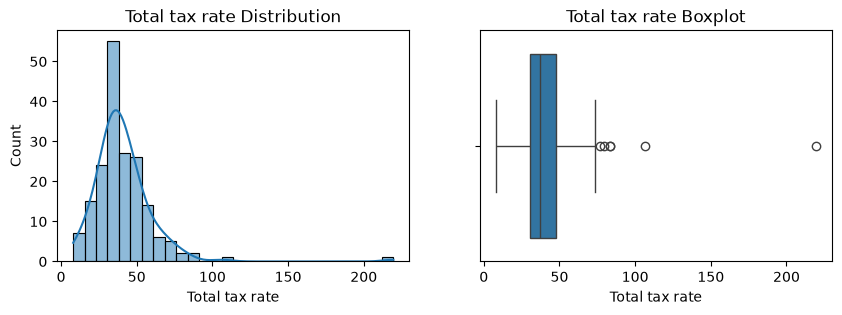

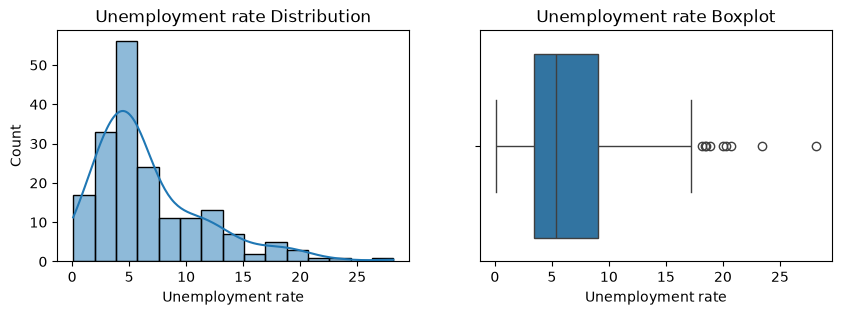

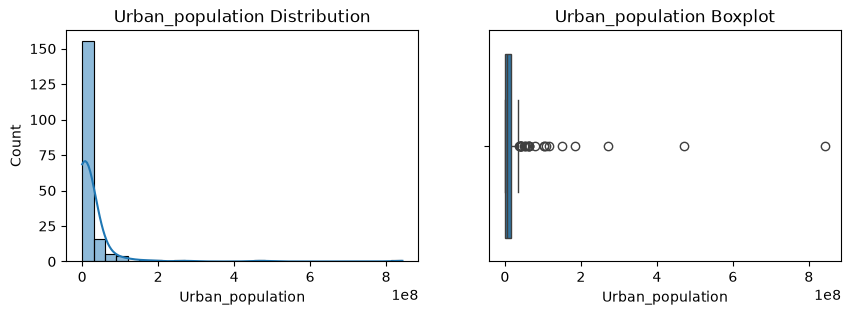

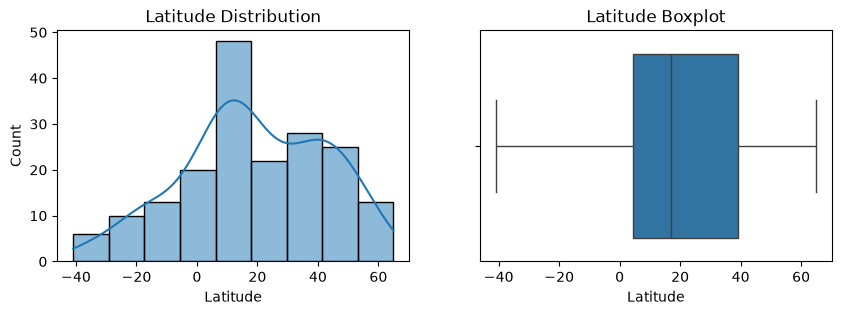

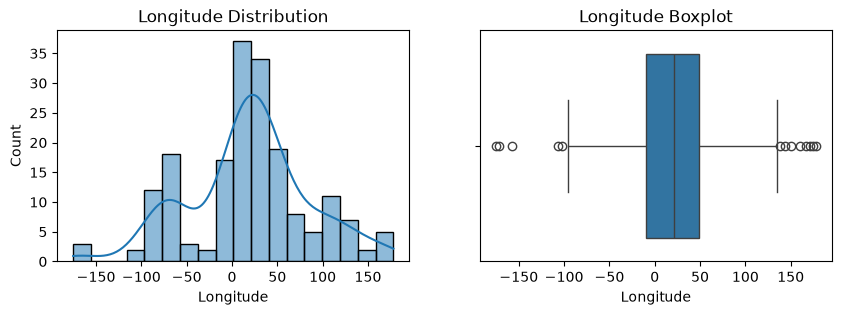

In [5]:
#Checking the distribution of numerical columns.
numeric_cols = df.select_dtypes(include=['int', 'int64', 'float64']).columns

for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    
    sns.histplot(df[col], kde=True, ax=axes[0])
    axes[0].set_title(f'{col} Distribution')
    
    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f'{col} Boxplot')

    plt.show()
    plt.close(fig)

In [6]:
#Checking the outliers of some features where we found high skeweness to the right.

outlier_check = ['Density\n(P/Km2)', 'Land Area(Km2)', 'Armed Forces size', 
               'Co2-Emissions', 'GDP', 'Population', 'Urban_population']

for col in outlier_check:
    top5 = df.nlargest(5, col)[['Country', col]]
    print(f'--- Top 5 by {col} ---')
    print(top5.to_string(index=False))

--- Top 5 by Density
(P/Km2) ---
   Country  Density\n(P/Km2)
 Singapore              8358
   Bahrain              2239
  Maldives              1802
     Malta              1380
Bangladesh              1265
--- Top 5 by Land Area(Km2) ---
      Country  Land Area(Km2)
       Russia        17098240
       Canada         9984670
United States         9833517
        China         9596960
       Brazil         8515770
--- Top 5 by Armed Forces size ---
      Country  Armed Forces size
        India            3031000
        China            2695000
  North Korea            1469000
       Russia            1454000
United States            1359000
--- Top 5 by Co2-Emissions ---
      Country  Co2-Emissions
        China      9893038.0
United States      5006302.0
        India      2407672.0
       Russia      1732027.0
        Japan      1135886.0
--- Top 5 by GDP ---
       Country          GDP
 United States 2.142770e+13
         China 1.991000e+13
         Japan 5.081770e+12
       Ger

Now i will create a correlation matrix. It is useful for various reasons. First of all it is useful to get various insights about the relationship
between features. Second of all, it is important to detect collinearities. For example, CPI and CPI Change (%) features are linearly related.
When independent variables are correlated each other within a certain degree then we have to be careful to not use both of them as predictors. 
Otherwise our estimates would be unstable and we would lost to be able to interpret which of the values drives the outcome. 

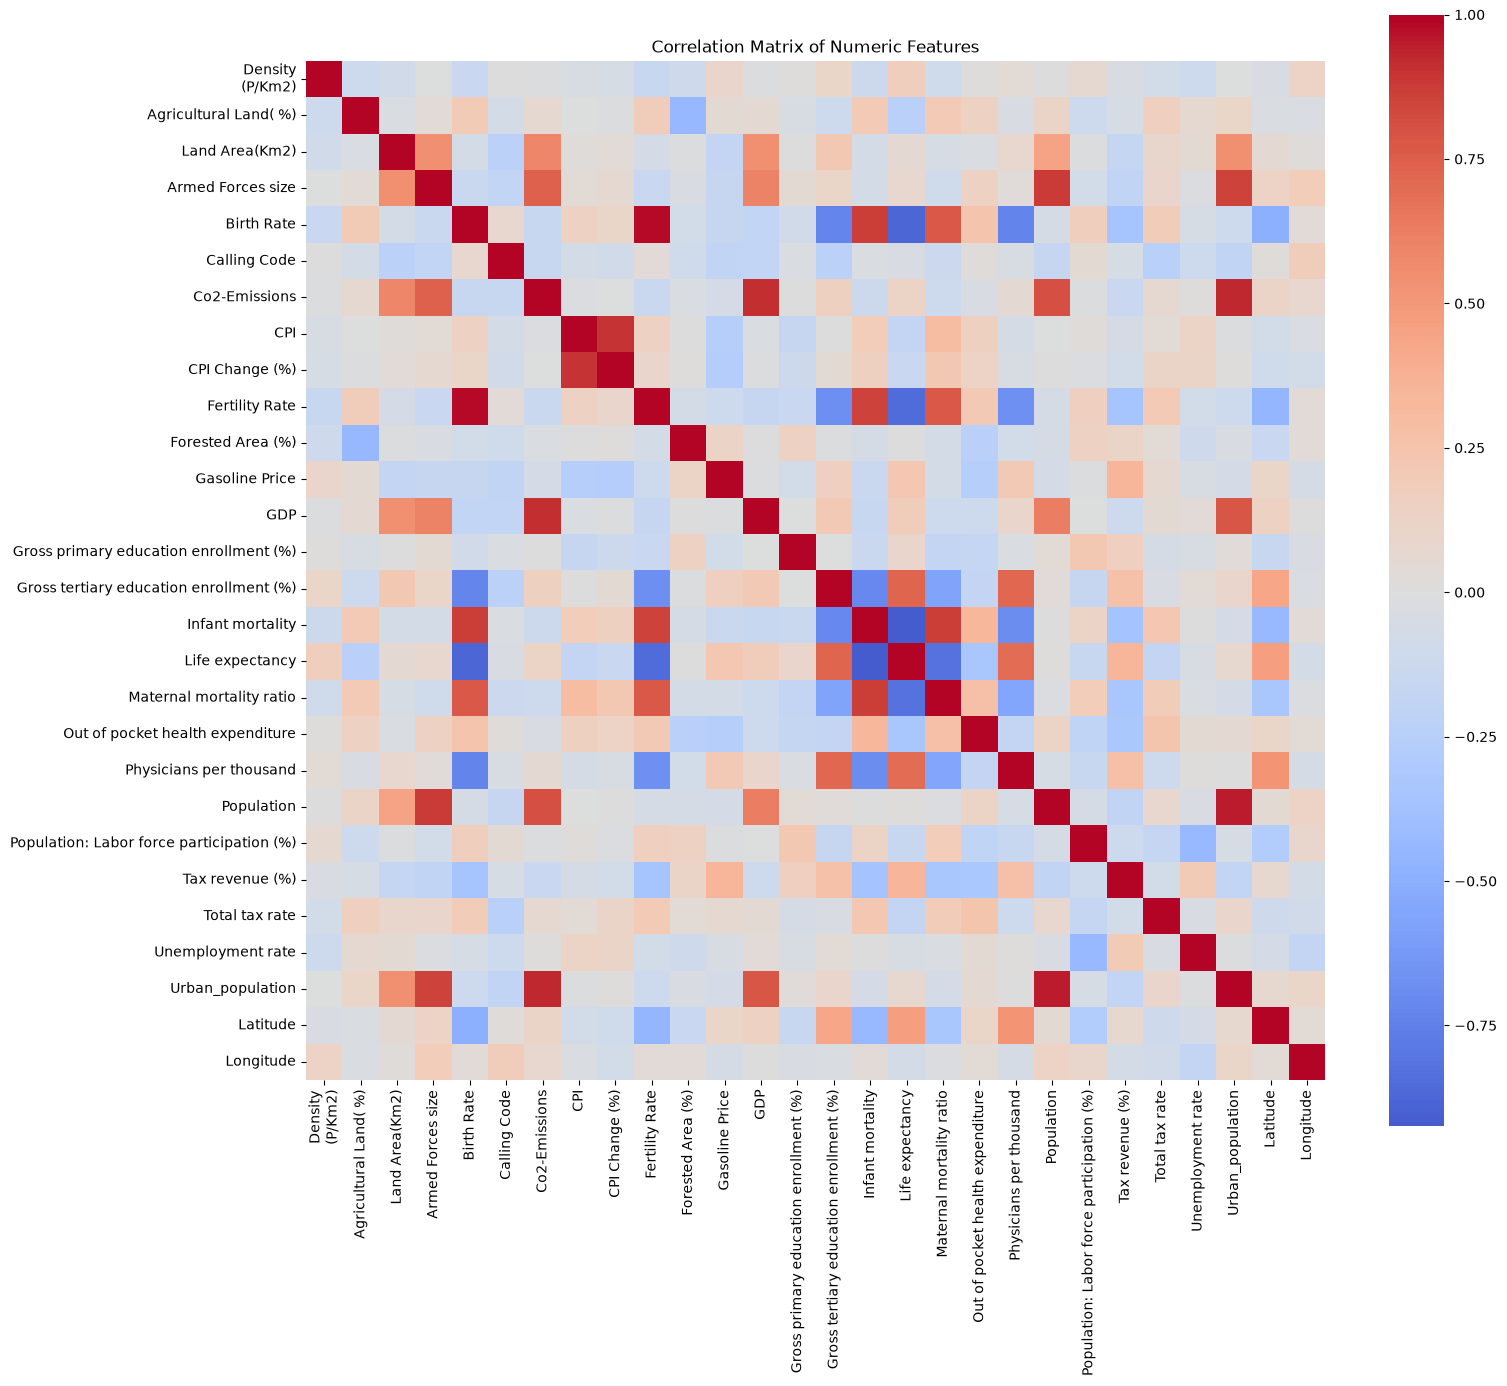

In [7]:
#Creating a correlation matrix to see relationship between features.
corr_matrix = df[numeric_cols].corr()
plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0, square=True)
plt.title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

In [8]:
#Dropping the features below because they are highly positive/negative correlated with Fertility Rate and Life Expectancy, so we don't need them.
df = df.drop(columns=['Birth Rate', 'Infant mortality', 'Maternal mortality ratio'])

#There are countries with big economies such as India, but raw GDP doesn't explain how the money actually distributes within people. So: GDP per Capita.
df['GDP_per_capita'] = df['GDP'] / df['Population']
#--Implementing log transformation because of the right-skewness of GDP.
df['GDP_per_capita'] = np.log1p(df['GDP_per_capita'])

#It is highly posivite correlated with the CPI, don't need it.
df = df.drop(columns=['CPI Change (%)'])

Here, i choose some features that defines some overall life-quality elements. I didn't want to choose statistics that depicts the countries army size,
overall economic power, population etc... I tried to choose features that pointing out a good life quality. For that spesific purpose, instead of GDP feature, i created GDP Per Capita feature. 

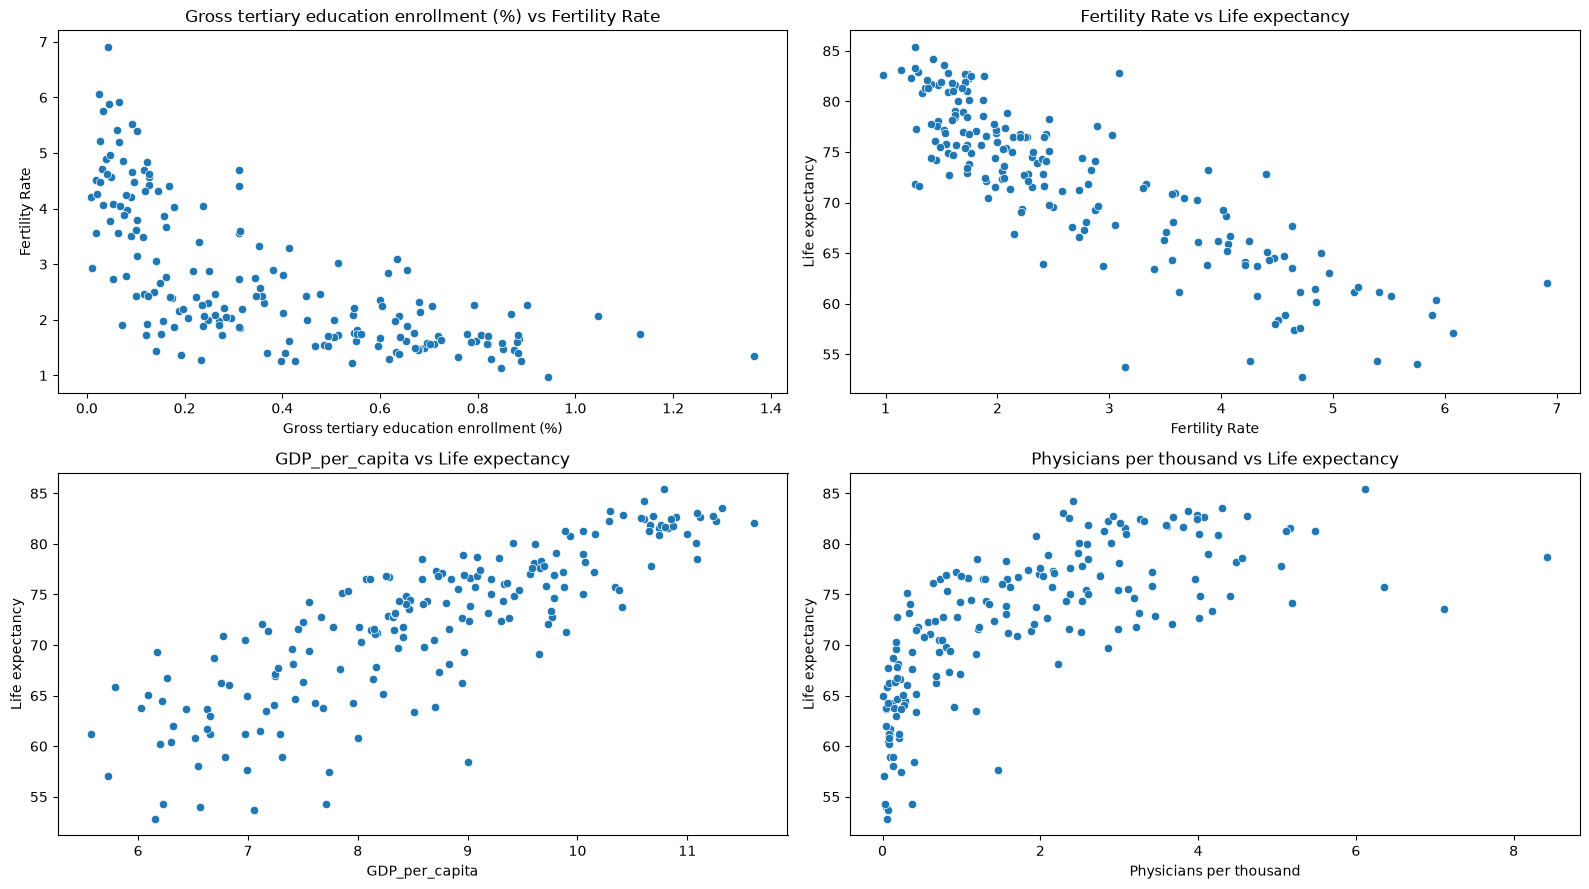

In [9]:
#Visualizing and testing some well defined relationships.

comparison =  [
    ('Gross tertiary education enrollment (%)', 'Fertility Rate'),
    ('Fertility Rate', 'Life expectancy'),
    ('GDP_per_capita', 'Life expectancy'),
    ('Physicians per thousand', 'Life expectancy'),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
axes = axes.flatten()

for i, (x, y) in enumerate(comparison):
    sns.scatterplot(data=df, x=x, y=y, ax=axes[i])
    axes[i].set_title(f'{x} vs {y}')

plt.tight_layout()
plt.show()

In [10]:
#Defining features we will use for clustering.
features = ['Fertility Rate', 'Life expectancy', 'GDP_per_capita', 'Gross tertiary education enrollment (%)', 'Physicians per thousand']

df_cluster = df[['Country'] + features].copy()
df_cluster.describe()

,Fertility Rate,Life expectancy,GDP_per_capita,Gross tertiary education enrollment (%),Physicians per thousand
count,185.000000,185.000000,185.000000,185.000000,185.000000
mean,2.703892,72.232973,8.650053,0.379627,1.818865
std,1.279453,7.480885,1.448462,0.290618,1.651716
min,0.980000,52.800000,5.569289,0.008000,0.010000
25%,1.710000,66.900000,7.505243,0.123000,0.340000
50%,2.250000,73.200000,8.692173,0.312000,1.460000
75%,3.590000,77.400000,9.757158,0.631000,2.890000
max,6.910000,85.400000,11.609811,1.366000,8.420000


Now, in order to cluster our data, we have to scale our values. StandardScaler() function scales our data to a standard deviation of 1. It subtracts the
mean from all values and the new mean becomes 0 (that means it creates a normal distrubition).
I personally decided to give scaled GDP Per Capita feature a weight of 2.5. Because i wouldn't be able to find many useful metrics that points out 
life quality, and from the ones that i found i couldn't find any other useful economic metric than GDP Per Capita. 

In [11]:
#Scaling our values.
scaler = StandardScaler()
values_scaled = scaler.fit_transform(df_cluster[features])

df_scaled = pd.DataFrame(values_scaled, columns=features, index=df_cluster.index)
df_scaled['Country'] = df_cluster['Country'].values
#Multiplying the GDP per capita with 2.5 because we don't have enough metrics for economic quality. So decided to give some weight to the only economic metric.
df_scaled['GDP_per_capita'] = df_scaled['GDP_per_capita'] * 2.5

df_scaled.describe()

,Fertility Rate,Life expectancy,GDP_per_capita,Gross tertiary education enrollment (%),Physicians per thousand
count,1.850000e+02,1.850000e+02,1.850000e+02,1.850000e+02,1.850000e+02
mean,-4.680940e-17,1.773956e-15,-8.257659e-16,9.121832e-17,2.880579e-17
std,1.002714e+00,1.002714e+00,2.506784e+00,1.002714e+00,1.002714e+00
min,-1.351022e+00,-2.604733e+00,-5.331732e+00,-1.282219e+00,-1.098115e+00
25%,-7.789178e-01,-7.148145e-01,-1.981267e+00,-8.854366e-01,-8.977805e-01
50%,-3.557172e-01,1.296172e-01,7.289538e-02,-2.333326e-01,-2.178576e-01
75%,6.944471e-01,6.925717e-01,1.916015e+00,8.673086e-01,6.502584e-01
max,3.296347e+00,1.764866e+00,5.122312e+00,3.403269e+00,4.007378e+00


Now, in order to visualize how the 'Ward' method clusters the countries, i used the dendrogram graph. The 'Ward Method' calculates distance between two clusters by looking at the variance increase while trying possible pairs. The method goes bottom to top, ends with the one cluster. As we can see it
starts on the bottom with so many different clusters, then it ends with the one cluster with the color blue. 

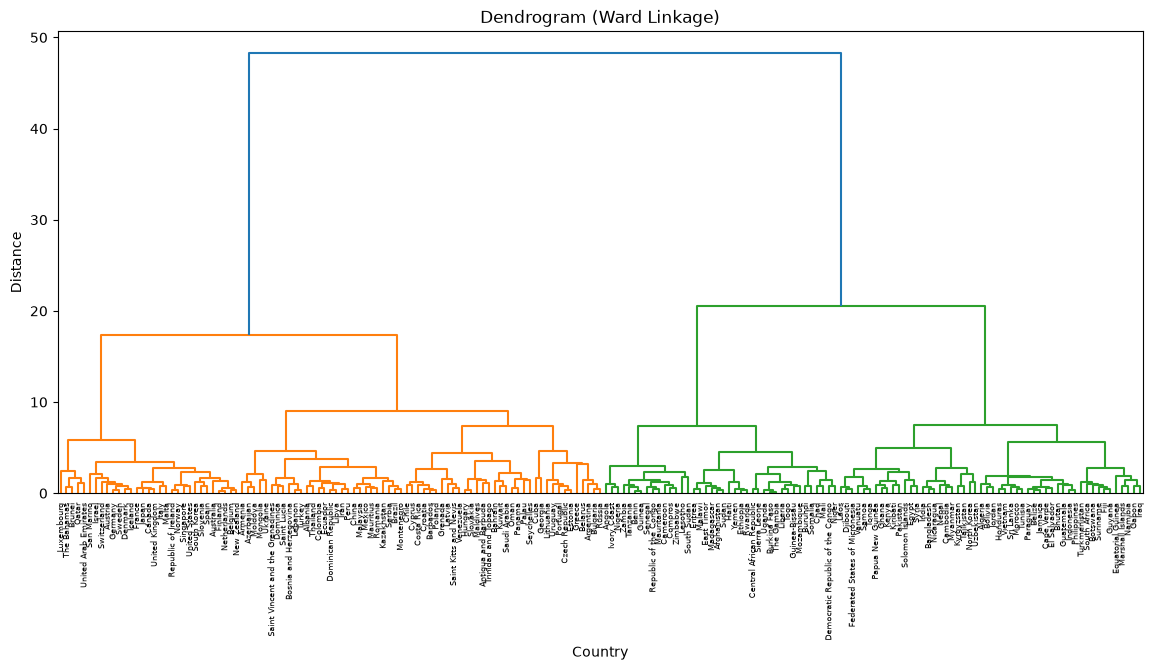

In [12]:
#Creating dendrogram graph to define the amount of clusters, and of course see the points where the algorthm seperates countries. 

X = df_scaled[features].values 
#--'Ward' method calculates the variances between countries, compatible with our example. (Only euclidian distance)
Z = linkage(X, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=df_scaled['Country'].values, leaf_font_size=6)
plt.title('Dendrogram (Ward Linkage)')
plt.xlabel('Country')
plt.ylabel('Distance')
plt.show()

But, since there are many countries to interpret, using silhouette score to determine the amount of clusters is more compatible. As you can see in the table, best performance we got starts with 2 clusters with score of '0.483943' and goes on with 3 clusters with score of '0.382401', 4 clusters with '0.346865' etc... Well, there are significant drop between 2 and 3, and also a moderate drop between 3 and 4 but i will choose cluster 4 because it is easy to interpret 4 clusters than 3 for this spesific work because countries vary a lot in terms of life quality.

In [13]:
#Using silhoutte score method for determining the number of clusters.

results = []
for k in range(2, 11):
    labels = fcluster(Z, t=k, criterion='maxclust')
    score = silhouette_score(X, labels)
    results.append({'k': k, 'silhouette_score': score})

results_df = pd.DataFrame(results)
results_df.set_index('k')

,silhouette_score
k,
2,0.483943
3,0.382401
4,0.346865
5,0.292088
6,0.249243
7,0.232407
8,0.236482
9,0.242463
10,0.240606


Now using the hierachial clustering with the 'Ward Method' and given cluster amount of 4 i defined our cluster and gave a name to them.
In the below you can see the overall statistics of features by the clusters. For example High Life Quality cluster has the lowest fertility rate and
highest GDP Per Capita while Poor Life Quality cluster has the highest fertility rate by far and lowest GDP Per Capita, lowest GTEE and by far lowest Physicians Per Thousand. The things that seperates Upper-Middle and Developing Country are mostyle the GTEE and Physicians per Thousand, but still countries within Developing Country clusters has way more life expectancy and and physician than countries within Poor Life Quality cluster.

In [14]:
#Seperating countries to 4 clusters and assigning accordingly.

cluster_labels = fcluster(Z, t=4, criterion='maxclust')

cluster_names = {
    1: 'High Life Quality',
    2: 'Upper-Middle Life Quality',
    3: 'Poor Life Quality',
    4: 'Developing Country'
}

df_scaled['Cluster'] = cluster_labels
df_cluster['Cluster'] = cluster_labels
df['Cluster'] = cluster_labels

df_scaled['Cluster'] = df_scaled['Cluster'].map(cluster_names)
df_cluster['Cluster'] = df_cluster['Cluster'].map(cluster_names)
df['Cluster'] = df['Cluster'].map(cluster_names)

In [15]:
cluster_summary = df_cluster.groupby('Cluster')[['Fertility Rate', 'Life expectancy', 'GDP_per_capita','Gross tertiary education enrollment (%)', 
                                                 'Physicians per thousand']].mean()

cluster_summary

,Fertility Rate,Life expectancy,GDP_per_capita,Gross tertiary education enrollment (%),Physicians per thousand
Cluster,,,,,
Developing Country,2.857308,70.473077,8.066371,0.216462,0.875769
High Life Quality,1.594839,81.561290,10.786919,0.670032,3.362903
Poor Life Quality,4.675250,61.630000,6.715542,0.081825,0.203000
Upper-Middle Life Quality,1.857903,75.885484,9.319230,0.563403,2.880323


As we can see clusters are very well-differentiated. PCA helped us to visualize our model by reducing into 2D.

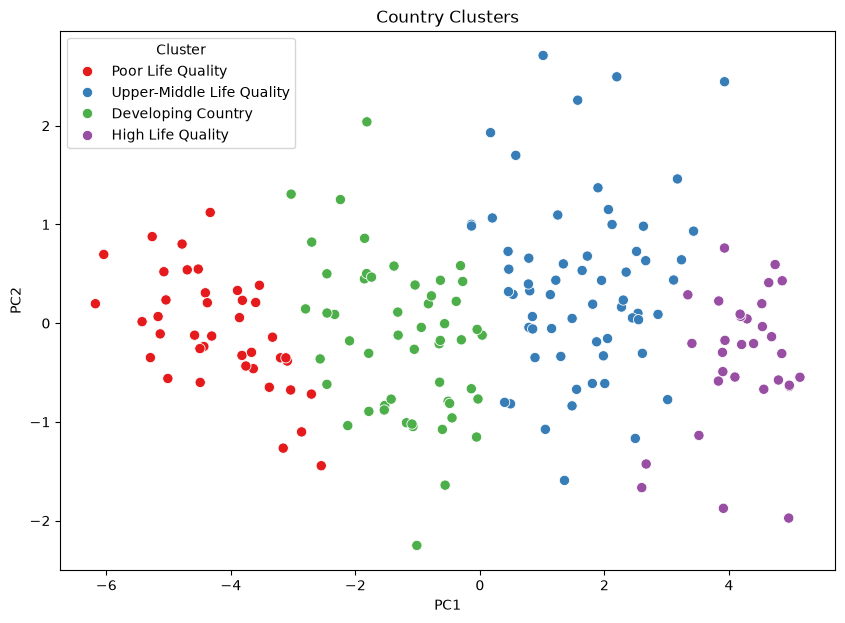

In [16]:
#Visualizing the clusters in 2D.

pca = PCA(n_components=2)
pca_result = pca.fit_transform(X)

df_scaled['PC1'] = pca_result[:, 0]
df_scaled['PC2'] = pca_result[:, 1]

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df_scaled, x='PC1', y='PC2', hue='Cluster', palette='Set1', s=55)
plt.title('Country Clusters')
plt.show()

Rest below consists visualization of clusters by using the features we didn't use. Even i didn't include them as a indicator for life quality, still 
there are interesting results which i explained in-depth in the PDF.

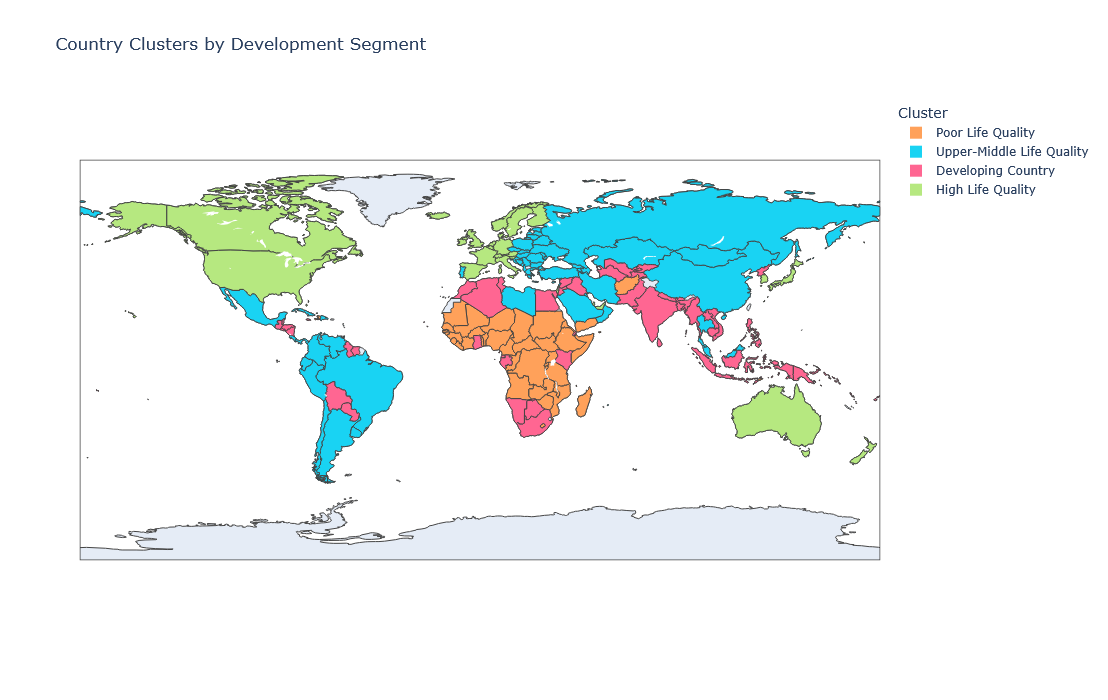

In [17]:
df_cluster['Cluster'] = df_cluster['Cluster'].astype(str)

fig = px.choropleth(
    df_cluster,
    locations='Country',
    locationmode='country names',
    color='Cluster', 
    title='Country Clusters by Development Segment',
    hover_name='Country',
    category_orders={'Cluster': ['1', '2', '3', '4']}
)


fig.update_layout(legend_title_text='Cluster', width=1200, height=700)


fig.show()

In [18]:
for cluster in sorted(df_cluster['Cluster'].unique()):
    print(f"\n--- Cluster {cluster} ---\n")
    print(df_cluster[df_cluster['Cluster'] == cluster]['Country'].tolist())


--- Cluster Developing Country ---

['Algeria', 'Bangladesh', 'Belize', 'Bhutan', 'Bolivia', 'Botswana', 'Cape Verde', 'Cambodia', 'Djibouti', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Fiji', 'Gabon', 'Ghana', 'Guatemala', 'Guyana', 'Honduras', 'India', 'Indonesia', 'Iraq', 'Jamaica', 'Jordan', 'Kenya', 'Kiribati', 'Kyrgyzstan', 'Laos', 'Marshall Islands', 'Federated States of Micronesia', 'Morocco', 'Myanmar', 'Namibia', 'Nepal', 'Nicaragua', 'North Korea', 'Pakistan', 'Papua New Guinea', 'Paraguay', 'Philippines', 'Samoa', 'Solomon Islands', 'South Africa', 'Sri Lanka', 'Suriname', 'Syria', 'Tajikistan', 'Tonga', 'Tunisia', 'Turkmenistan', 'Uzbekistan', 'Vanuatu', 'Vietnam']

--- Cluster High Life Quality ---

['Australia', 'Austria', 'The Bahamas', 'Belgium', 'Brunei', 'Canada', 'Denmark', 'Finland', 'France', 'Germany', 'Iceland', 'Republic of Ireland', 'Israel', 'Italy', 'Japan', 'Luxembourg', 'Malta', 'Netherlands', 'New Zealand', 'Norway', 'Qatar', 'San Marino', 'Singapore'

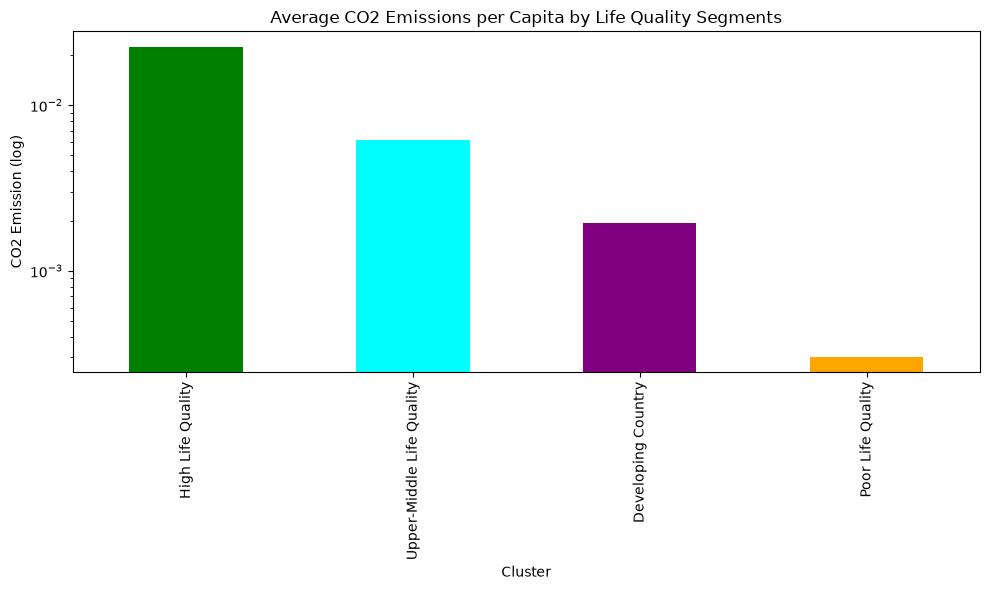

In [19]:
df['Co2_per_capita'] = df['Co2-Emissions'] / df['Population'] 
co2_per_cap = df.groupby('Cluster')['Co2_per_capita'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
co2_per_cap.plot(kind='bar', color=['green', 'cyan', 'purple', 'orange'])
plt.yscale('log')
plt.title('Average CO2 Emissions per Capita by Life Quality Segments' )
plt.ylabel('CO2 Emission (log)')
plt.xlabel('Cluster')
plt.tight_layout()
plt.show()

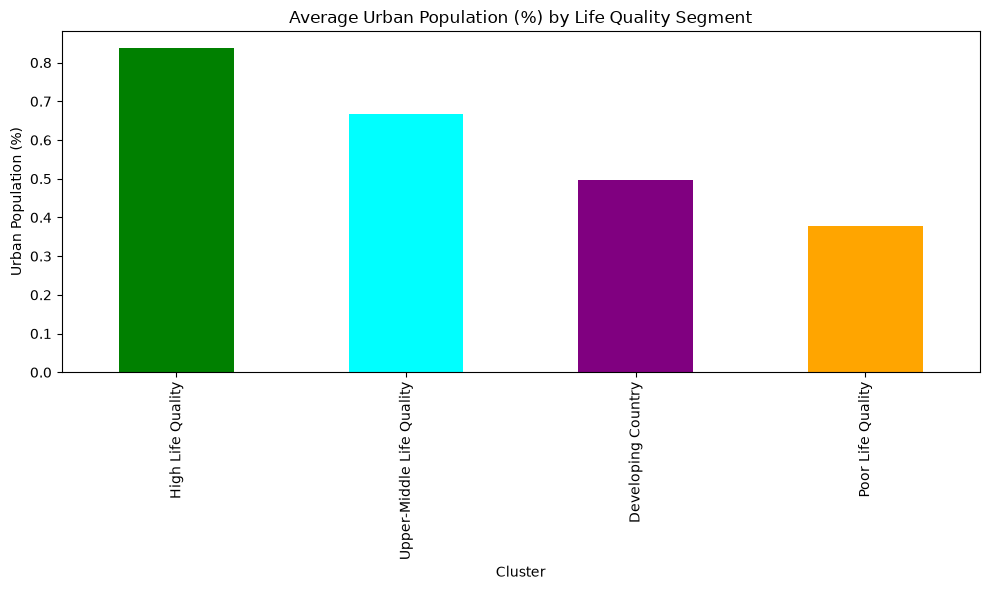

In [20]:
df['Urban_population_pct'] = df['Urban_population'] / df['Population']
urban_pop_pct = df.groupby('Cluster')['Urban_population_pct'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
urban_pop_pct.plot(kind='bar', color=['green', 'cyan', 'purple', 'orange'])
plt.title('Average Urban Population (%) by Life Quality Segment')
plt.ylabel('Urban Population (%)')
plt.xlabel('Cluster')
plt.tight_layout()
plt.show()

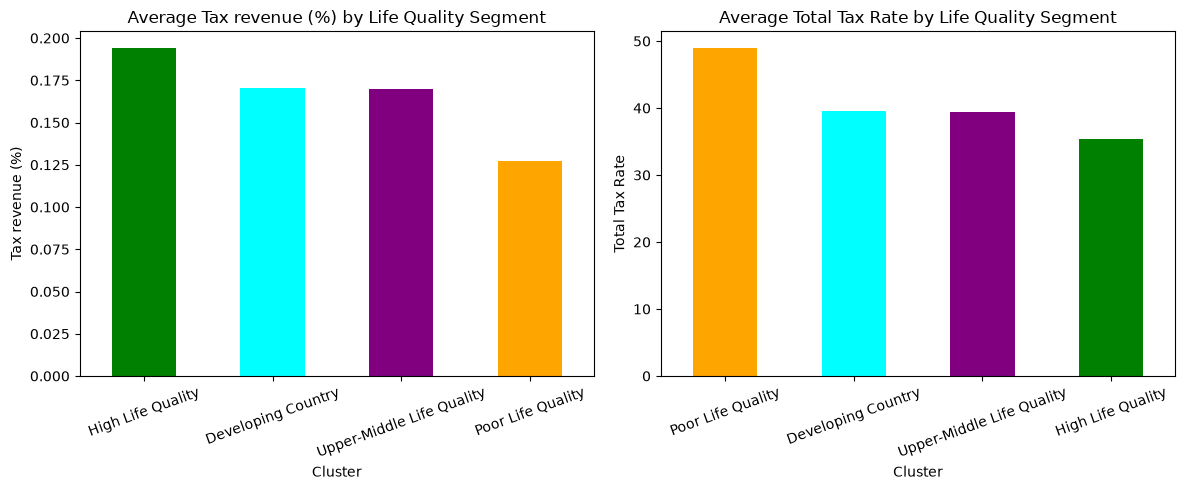

In [21]:
tax_by_cluster = df.groupby('Cluster')[['Tax revenue (%)', 'Total tax rate']].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

tax_by_cluster['Tax revenue (%)'].sort_values(ascending=False).plot(kind='bar', ax=axes[0], color=['green', 'cyan', 'purple', 'orange'])
axes[0].set_title('Average Tax revenue (%) by Life Quality Segment')
axes[0].set_ylabel('Tax revenue (%)')          
axes[0].tick_params(axis='x', rotation=20)

tax_by_cluster['Total tax rate'].sort_values(ascending=False).plot(kind='bar', ax=axes[1], color=['orange', 'cyan', 'purple', 'green'])
axes[1].set_title('Average Total Tax Rate by Life Quality Segment')
axes[1].set_ylabel('Total Tax Rate')          
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

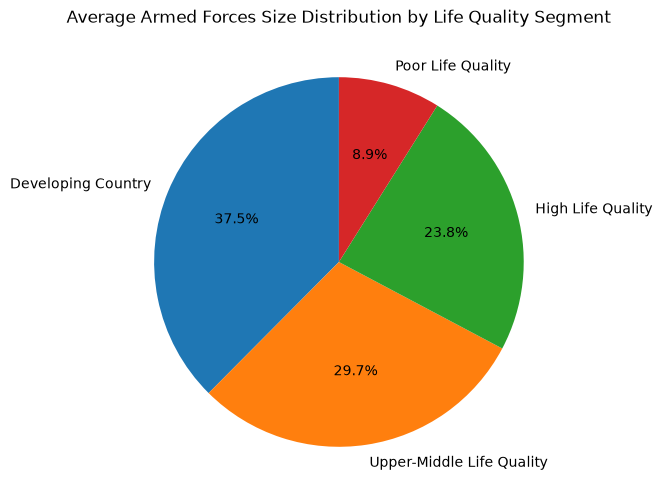

In [22]:
gdp_cluster = (df.groupby('Cluster')['Armed Forces size'].mean().sort_values(ascending=False))

plt.figure(figsize=(6, 6))
gdp_cluster.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.ylabel('')  
plt.title('Average Armed Forces Size Distribution by Life Quality Segment')
plt.show()